# Component 2 – Drift model experiments
Goal: predict drift distance (m) from six inputs known before spraying.
Inputs: crosswind, height, swath, temperature, RH, droplet class. Target: drift_distance_m.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split

DATA = Path.cwd().parent / "data" / "agdrift_dataset_v3_final.csv"
df = pd.read_csv(DATA)

DROPLET_CODE = {"VF-F": 0, "F-M": 1, "M-C": 2, "C-VC": 3}
df["droplet_code"] = df["droplet_class"].map(DROPLET_CODE)

FEATURES = ["crosswind_ms", "height_m", "swath_m", "temp_c", "rh_pct", "droplet_code"]
TARGET = "drift_distance_m"
SEED = 42
print(df.shape)

(5000, 18)


## M1 – Train/test split
80 % of runs are used to train the model, 20 % are kept aside to test it on unseen data.
The random seed makes the split repeatable.

In [2]:
train, test = train_test_split(df, test_size=0.2, random_state=SEED)
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (4000, 6) | Test: (1000, 6)


In [3]:
cols = FEATURES + [TARGET]
ks = pd.DataFrame([[r.statistic, r.pvalue] for r in [stats.ks_2samp(train[c], test[c]) for c in cols]], index=cols, columns=["KS_stat", "p_value"]).round(3)
ks["similar (p > 0.05)"] = ks["p_value"] > 0.05
ks

,KS_stat,p_value,similar (p > 0.05)
crosswind_ms,0.024,0.741,True
height_m,0.038,0.207,True
swath_m,0.047,0.055,True
temp_c,0.028,0.529,True
rh_pct,0.039,0.173,True
droplet_code,0.028,0.563,True
drift_distance_m,0.036,0.247,True


## M2 – Baseline models
**What:** score two simple models – an average guess and linear regression.

**Why:** they give the minimum score the main model must beat.
Scores: R² (share of drift variation explained, 1 = perfect), MAE (average error in metres), RMSE (error that punishes big mistakes).

In [4]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

results = []
def evaluate(name, model): model.fit(X_train, y_train); pred = model.predict(X_test); r2 = r2_score(y_test, pred); mae = mean_absolute_error(y_test, pred); rmse = np.sqrt(mean_squared_error(y_test, pred)); results.append({"model": name, "R2": round(r2, 3), "MAE_m": round(mae, 2), "RMSE_m": round(rmse, 2)}); print(f"{name:20s} R² = {r2:.3f} | MAE = {mae:.2f} m | RMSE = {rmse:.2f} m"); return pred

In [5]:
pred_avg = evaluate("Average guess", DummyRegressor(strategy="mean"))
pred_lin = evaluate("Linear regression", LinearRegression())

Average guess        R² = -0.001 | MAE = 9.17 m | RMSE = 11.47 m
Linear regression    R² = 0.839 | MAE = 3.76 m | RMSE = 4.60 m


**Findings:** The average-guess baseline explains none of the variation (R² ≈ 0, MAE 9.17 m). Linear regression
reaches R² = 0.839 (MAE 3.76 m, RMSE 4.60 m), already above the project target of 0.7. However, a linear model
gives each input the same effect for every droplet size, so it cannot capture the droplet × crosswind
interaction found in the EDA. The main model must clearly beat R² = 0.839.

## M3 – Random Forest
**What:** train a Random Forest (300 decision trees whose predictions are averaged).
**Why:** it can learn non-linear effects and interactions (e.g. wind matters more for fine droplets), which the linear model cannot.

In [6]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)
pred_rf = evaluate("Random Forest", rf)

Random Forest        R² = 0.990 | MAE = 0.83 m | RMSE = 1.17 m


In [7]:
pd.DataFrame(results).set_index("model")

,R2,MAE_m,RMSE_m
model,,,
Average guess,-0.001,9.17,11.47
Linear regression,0.839,3.76,4.60
Random Forest,0.990,0.83,1.17


**Findings:** The Random Forest reaches R² = 0.990 on the test set (MAE 0.83 m, RMSE 1.17 m), compared with 0.839
(MAE 3.76 m) for linear regression – the average error is about 4.5× smaller. This confirms that the non-linear
effects and the droplet × crosswind interaction matter. The very high accuracy partly reflects that the data
come from a deterministic simulation without field noise; real-field accuracy will be lower and will be checked
with Suleco flight data (Dataset B).

In [8]:
train_r2 = r2_score(y_train, rf.predict(X_train))
print(f"Train R² = {train_r2:.3f} | Test R² = {r2_score(y_test, pred_rf):.3f}")

Train R² = 0.998 | Test R² = 0.990


In [9]:
from sklearn.model_selection import KFold, GroupKFold, cross_val_score
X_all, y_all = df[FEATURES], df[TARGET]
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_r2 = cross_val_score(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1), X_all, y_all, cv=cv, scoring="r2")
cv_mae = -cross_val_score(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1), X_all, y_all, cv=cv, scoring="neg_mean_absolute_error")
print("R² per fold:", cv_r2.round(3), "| mean =", round(cv_r2.mean(), 3), "±", round(cv_r2.std(), 3))
print("MAE per fold:", cv_mae.round(2), "| mean =", round(cv_mae.mean(), 2), "m")

R² per fold: [0.989 0.987 0.988 0.99  0.987] | mean = 0.988 ± 0.001
MAE per fold: [0.84 0.86 0.9  0.85 0.9 ] | mean = 0.87 m


In [10]:
gcv = GroupKFold(n_splits=5)
g_r2 = cross_val_score(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1), X_all, y_all, cv=gcv, groups=df["datetime"], scoring="r2")
print("Grouped R² per fold:", g_r2.round(3), "| mean =", round(g_r2.mean(), 3))

Grouped R² per fold: [0.99  0.988 0.99  0.99  0.986] | mean = 0.989


## M5 – Feature importance
**What:** permutation importance – shuffle one input at a time and measure how much the test R² drops.
**Why:** to check the model relies on the same inputs the EDA identified as important (physically sensible).

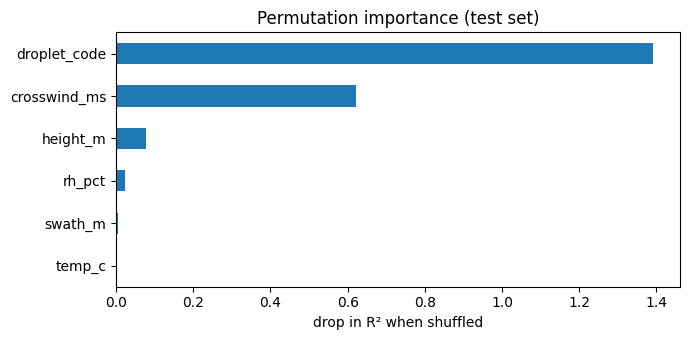

droplet_code    1.392
crosswind_ms    0.621
height_m        0.077
rh_pct          0.023
swath_m         0.004
temp_c          0.004
dtype: float64

In [11]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
plt.figure(figsize=(7, 3.5)); imp.plot(kind="barh"); plt.xlabel("drop in R² when shuffled"); plt.title("Permutation importance (test set)"); plt.tight_layout()
plt.savefig("fig_m5_importance.png", dpi=150, bbox_inches="tight"); plt.show()
imp.sort_values(ascending=False).round(3)

**Findings:** Permutation importance ranks droplet class first (R² drop 1.39), crosswind second (0.62) and height
third (0.08); RH (0.02), swath and temperature (≈0.004) contribute little.Droplet size and crosswind are therefore the
key controls for reducing drift.

In [12]:
import joblib
SAVE_DIR = Path.cwd() / "saved"
SAVE_DIR.mkdir(exist_ok=True)
joblib.dump(rf, SAVE_DIR / "drift_rf.joblib")
print("Saved:", SAVE_DIR / "drift_rf.joblib", "| size:", round((SAVE_DIR / "drift_rf.joblib").stat().st_size / 1e6, 1), "MB")

Saved: c:\Projects\AI-Driven-Drone-System-for-Precision-Spraying-in-Sri-Lankan-Tea-Plantations-J26-DS-346\component2_wind_spraying\drift_model\saved\drift_rf.joblib | size: 109.2 MB


more models

## Model comparison
**What:** compare ten regression models using the same 5-fold cross-validation on the training set.
**Why:** to choose the best model fairly, based on accuracy, stability and speed – not just assume Random Forest is best.
The test set is not used here; it is kept for the final evaluation.

In [16]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import cross_validate
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

models = {
"Linear regression": LinearRegression(),
"Random Forest": RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
"Gradient Boosting": GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, random_state=SEED),
"XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, random_state=SEED, n_jobs=-1),
"LightGBM": LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=SEED, verbose=-1),
}
print(len(models), "models ready")

5 models ready


In [17]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, m in models.items(): s = cross_validate(m, X_train, y_train, cv=cv5, scoring={"r2": "r2", "mae": "neg_mean_absolute_error"}, n_jobs=-1); rows.append({"model": name, "CV_R2": round(s["test_r2"].mean(), 3), "CV_R2_std": round(s["test_r2"].std(), 3), "CV_MAE_m": round(-s["test_mae"].mean(), 2), "fit_time_s": round(s["fit_time"].mean(), 2)}); print(name, "done")
comparison = pd.DataFrame(rows).set_index("model").sort_values("CV_MAE_m")
comparison

Linear regression done
Random Forest done
Gradient Boosting done
XGBoost done
LightGBM done


,CV_R2,CV_R2_std,CV_MAE_m,fit_time_s
model,,,,
XGBoost,0.989,0.001,0.86,0.60
LightGBM,0.989,0.001,0.88,2.76
Random Forest,0.987,0.001,0.89,2.38
Gradient Boosting,0.988,0.001,0.90,2.95
Linear regression,0.835,0.006,3.84,0.01


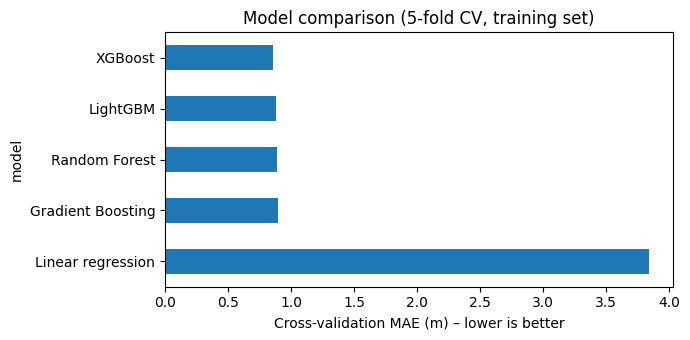

In [18]:
plt.figure(figsize=(7, 3.5)); comparison["CV_MAE_m"].sort_values(ascending=False).plot(kind="barh"); plt.xlabel("Cross-validation MAE (m) – lower is better"); plt.title("Model comparison (5-fold CV, training set)"); plt.tight_layout()
plt.savefig("fig_m3b_model_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

**Findings:** All four tree-based models perform almost equally well (CV MAE 0.86–0.90 m, R² 0.987–0.989, all
stable with std 0.001), about 4.5× more accurate than linear regression (MAE 3.84 m). XGBoost has the lowest error
(MAE 0.86 m, R² 0.989) and the shortest training time (0.6 s), and produces a much smaller saved model than Random
Forest. Because the accuracy differences are very small, XGBoost is chosen mainly for its speed and compact size,
which suit deployment in the drone system.

## M3c – Hyperparameter tuning (XGBoost)
**What:** try 30 random combinations of XGBoost settings, each scored with 5-fold cross-validation on the training set.
**Why:** to find the best settings instead of using default guesses. The test set is still not used.

In [19]:
from sklearn.model_selection import RandomizedSearchCV
param_dist = {
"n_estimators": [300, 500, 800, 1200],
"learning_rate": [0.02, 0.05, 0.1],
"max_depth": [3, 4, 5, 6, 8],
"subsample": [0.7, 0.85, 1.0],
"colsample_bytree": [0.7, 0.85, 1.0],
"min_child_weight": [1, 3, 5],
}
search = RandomizedSearchCV(XGBRegressor(random_state=SEED, n_jobs=-1), param_dist, n_iter=30, cv=cv5, scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=1, verbose=1)
search.fit(X_train, y_train)
print("Best settings:", search.best_params_)
print("Best CV MAE:", round(-search.best_score_, 3), "m  (default XGBoost: 0.86 m)")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best settings: {'subsample': 0.7, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
Best CV MAE: 0.836 m  (default XGBoost: 0.86 m)


In [20]:
final_model = search.best_estimator_
pred_final = final_model.predict(X_test)
print(f"Final XGBoost – Test R² = {r2_score(y_test, pred_final):.3f} | MAE = {mean_absolute_error(y_test, pred_final):.2f} m | RMSE = {np.sqrt(mean_squared_error(y_test, pred_final)):.2f} m")
print(f"Train R² = {r2_score(y_train, final_model.predict(X_train)):.3f}")

Final XGBoost – Test R² = 0.992 | MAE = 0.77 m | RMSE = 1.04 m
Train R² = 0.997


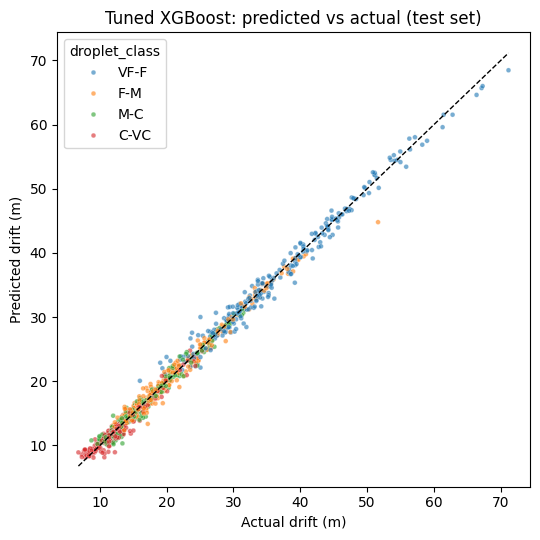

In [21]:
plt.figure(figsize=(5.5, 5.5))
sns.scatterplot(x=y_test, y=pred_final, hue=test["droplet_class"], hue_order=["VF-F", "F-M", "M-C", "C-VC"], s=12, alpha=0.6)
lims = [y_test.min(), y_test.max()]; plt.plot(lims, lims, "k--", lw=1)
plt.xlabel("Actual drift (m)"); plt.ylabel("Predicted drift (m)"); plt.title("Tuned XGBoost: predicted vs actual (test set)"); plt.tight_layout()
plt.savefig("fig_m6_pred_vs_actual.png", dpi=150, bbox_inches="tight"); plt.show()

In [22]:
err = test.assign(abs_error=np.abs(y_test - pred_final))
err.groupby("droplet_class")["abs_error"].agg(["mean", "median", "max"]).loc[["VF-F", "F-M", "M-C", "C-VC"]].round(2)

,mean,median,max
droplet_class,,,
VF-F,1.02,0.82,4.96
F-M,0.77,0.63,6.84
M-C,0.64,0.53,3.06
C-VC,0.64,0.43,3.31


In [23]:
SAVE_DIR = Path.cwd() / "saved"; SAVE_DIR.mkdir(exist_ok=True)
final_model.save_model(SAVE_DIR / "drift_xgb.json")
print("Saved drift_xgb.json –", round((SAVE_DIR / "drift_xgb.json").stat().st_size / 1e6, 2), "MB")

Saved drift_xgb.json – 1.46 MB
